# Notebook 2: Explainable AI (XAI) -- LIME on text data

## Course: Big Data Analytics
## University of Milano-Bicocca
## Degree Programme: Economics, Data Analysis and Management

---

### Introduction

A model can have a good accuracy and still make mistakes for a reason that nobody sees. In this notebook we:

1. **train** a black-box model that reads a sentence of a **customer review** (mobile phones on Amazon, restaurants on Yelp) and says whether it is **positive** or **negative** (*sentiment analysis*) (Part 1);
2. **open** it with **LIME**, *Local Interpretable Model-agnostic Explanations*: first **by hand**, to see every detail of how it works, then with the library, and we check whether the explanation can be **trusted** (*fidelity*) (Part 2);
3. **use** what LIME shows us to find a hidden bug and make the model **more accurate** (Part 3);
4. see the **limits** of LIME (Part 4).

> 📚 **The series**: 1. LIME · tabular → **2. LIME · text** (this notebook) → 3. SHAP · tabular → 4. SHAP · text. Notebooks 2 and 4 explain **the same text model**: same data, same training, only the explainer changes.

> ⏱️ **Run time.** This notebook runs a neural network thousands of times, but the sentences are short: *Run all* takes about 2 minutes on the free CPU of Colab (no GPU needed).

# IMAGINE: AN ONLINE SHOP USES A MODEL TO SEND EVERY NEGATIVE REVIEW TO ITS CUSTOMER SERVICE. THE MODEL READS "I WOULD NOT RECOMMEND THIS ITEM TO ANYONE" AND FILES IT AS PRAISE. HOW WOULD YOU FIND OUT WHY?

---

## Why do we need explanations?

A model that turns a sentence into hundreds of numbers is a **black box**: we see the input and the output, not the reasoning.

- 🐛 **Debugging**: the accuracy tells us *how often* the model is wrong, not *why*. An explanation shows which words drove a wrong prediction, and that is the first step to fix the model.
- 🔍 **Trust**: before a model sorts the reviews of real customers, a person must be able to check that it decides for the right reasons.

> **Global** explanations describe the whole model; **local** explanations answer the question *"why THIS prediction?"*. LIME is a **local** method.

In [ ]:
# ==========================================
# 1. SETUP: INSTALL AND IMPORT
# ==========================================

# lime is not pre-installed on Colab; sentence-transformers usually is (then pip only checks it)
!pip install lime sentence-transformers --quiet

import io                                # to read the downloaded zip file from memory
import re                                # regular expressions: to split sentences into words
import time
import urllib.request                    # to download the data
import warnings
import zipfile                           # to open the zip file of the data
import numpy as np                       # numbers and arrays
import pandas as pd                      # tables (DataFrame)
import matplotlib.pyplot as plt          # charts
from IPython.display import HTML, display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # scikit-learn's list of English stop words
from sklearn.preprocessing import FunctionTransformer             # turns a Python function into a pipeline step
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import accuracy_score
from sentence_transformers import SentenceTransformer             # the sentence-embedding model

from lime.lime_text import LimeTextExplainer                      # LIME for text

warnings.filterwarnings("ignore")    # hide technical warnings, to keep the output readable
np.random.seed(42)                   # fix the random numbers: same results at every run

# Colors of our own charts (a palette that colorblind readers can tell apart)
BLUE, ORANGE, RED, GRAY = "#2a78d6", "#eb6834", "#e34948", "#898781"
INK, GRID = "#52514e", "#e1e0d9"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_colwidth", 150)   # show long texts in full inside tables

def dumbbell(table, xlabel, title, fmt="{:.1%}"):
    # Helper for "before vs after" charts.
    # 'table' has one row per item and two columns: [before, after]. Each row becomes a line
    # with a gray dot (before) and a blue dot (after), and the two values written next to the dots.
    before, after = table.columns
    fig, ax = plt.subplots(figsize=(8, 1.2 + 0.55 * len(table)))
    for i, (a, b) in enumerate(table.values):
        ax.plot([a, b], [i, i], color="#c3c2b7", lw=2, zorder=1)                     # the line
        ax.scatter(a, i, s=110, color=GRAY, edgecolors="white", lw=2, zorder=2, label=before if i == 0 else None)
        ax.scatter(b, i, s=110, color=BLUE, edgecolors="white", lw=2, zorder=3, label=after if i == 0 else None)
        ax.annotate(fmt.format(a), (a, i), xytext=(0, 8), textcoords="offset points", ha="center", color=INK, fontsize=8)
        ax.annotate(fmt.format(b), (b, i), xytext=(0, -15), textcoords="offset points", ha="center", color=INK, fontsize=8)
    ax.set_yticks(range(len(table)), table.index)
    ax.set_ylim(-0.7, len(table) - 0.3)
    ax.set_xlabel(xlabel)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: fmt.format(v)))
    ax.set_title(title, loc="left", pad=26)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0))
    plt.tight_layout()
    plt.show()

def show_lime(explanation, **kwargs):
    # Shows LIME's interactive view (same as explanation.show_in_notebook(), but works with every IPython version)
    display(HTML(explanation.as_html(**kwargs)))

print("✅ Setup complete")

# 🏗️ Part 1 — Train the black box

This is the **training** of the sentiment model. **Notebook 4** (SHAP) repeats exactly this part (same data, same split, same random seeds), so it explains **the identical model**.

## 1.1 🛒 The data: customer reviews of products and restaurants

The **Sentiment Labelled Sentences** dataset (Kotzias et al., 2015, UCI Machine Learning Repository) contains single sentences taken from online reviews, each one labelled by hand as **positive** or **negative**. We use two of its sources:

| Source | What is reviewed | Sentences | Example |
| :--- | :--- | :---: | :--- |
| **Amazon** | mobile phones and accessories | 1,000 | *"Good case, Excellent value."* → positive |
| **Yelp** | restaurants | 1,000 | *"Crust is not good."* → negative |

Each source has 500 positive and 500 negative sentences. A few sentences appear twice (e.g. *"Works great."*): we keep one copy, so that the same sentence cannot end up both in the training and in the test set.

**The task (sentiment analysis)**: read a sentence and predict whether it is **positive** or **negative**. A company can use such a model to read thousands of reviews and send the **complaints** to its customer service automatically: every complaint the model misses is an unhappy customer that nobody answers.

In [ ]:
# ==========================================
# 2. LOAD THE REVIEW SENTENCES
# ==========================================

# The data is a small zip file (about 80 KB) on the UCI Machine Learning Repository: we download it into memory
URL_REVIEWS = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"
with urllib.request.urlopen(URL_REVIEWS) as response:
    archive = zipfile.ZipFile(io.BytesIO(response.read()))

# Each file of the zip has one sentence per line, in the form "sentence <TAB> label" (1 = positive, 0 = negative)
rows = []
for source, file_name in [("Amazon", "amazon_cells_labelled.txt"), ("Yelp", "yelp_labelled.txt")]:
    lines = archive.read("sentiment labelled sentences/" + file_name).decode("utf-8").splitlines()
    for line in lines:
        sentence, label = line.rsplit("\t", 1)            # split the line at its last TAB
        rows.append({"source": source, "sentence": sentence.strip(),
                     "label": "positive" if label.strip() == "1" else "negative"})

# Keep one copy of the sentences that appear twice
reviews = pd.DataFrame(rows).drop_duplicates("sentence").reset_index(drop=True)
sentences, labels = reviews["sentence"].tolist(), reviews["label"].tolist()

# 75% of the sentences to train, 25% to test; the same share of positive sentences in both parts
# (stratify); random_state=42 fixes the random split
X_train_txt, X_test_txt, y_train_txt, y_test_txt = train_test_split(
    sentences, labels, test_size=0.25, random_state=42, stratify=labels)

print(f"{len(sentences):,} sentences | train: {len(X_train_txt):,} | test: {len(X_test_txt):,}")
reviews.sample(5, random_state=43)          # five random sentences of the data

## 1.2 🧠 The black box: clean → embed → classify

Our model works in **three steps**:

| Step | What it does | Example |
| :--- | :--- | :--- |
| **1. Clean** | lower case, drop the punctuation, remove the **stop words**: very frequent words such as *the*, *is*, *of*, from a list of 318 English words provided by scikit-learn | `The battery life is great!` → `battery life great` |
| **2. Embed** | a pre-trained **sentence-embedding model** turns the sentence into **384 numbers** (an *embedding*) that describe its meaning: sentences with a similar meaning get similar numbers | `battery life great` → `[0.03, -0.11, ..., 0.07]` |
| **3. Classify** | a **logistic regression** turns the 384 numbers into **P(positive)**, the probability that the sentence is positive | → 0.95 |

- Removing stop words is a classic cleaning step of text pipelines: these words are very frequent and *usually* carry little meaning.
- The embedding model is `BAAI/bge-small-en-v1.5`, a small **transformer** (a neural network of the same family as BERT and GPT) with 33 million parameters, trained on millions of sentence pairs to put sentences with a similar meaning close to each other. It is downloaded from Hugging Face the first time (about 130 MB).
- A **logistic regression** computes a weighted sum of the 384 numbers and squeezes it between 0 and 1 to obtain a probability.

Nobody can say what each of the 384 numbers means: the three steps together are our **black box**. We evaluate it with the **accuracy** on the test set: the share of test sentences classified correctly (positive when P(positive) > 0.5).

In [ ]:
# ==========================================
# 3. TRAIN THE SENTIMENT BLACK BOX (CLEAN -> EMBED -> CLASSIFY)
# ==========================================

STOP_WORDS = ENGLISH_STOP_WORDS        # scikit-learn's list of 318 English stop words ('the', 'of', 'and', ...)

def clean(sentence, stop_words=STOP_WORDS):
    # STEP 1 - cleaning: lower case, keep only the words (punctuation is dropped), remove the stop words
    words = re.findall(r"\w+(?:'\w+)?", sentence.lower())          # "it's" stays one word
    return " ".join(w for w in words if w not in stop_words)

# STEP 2 - the sentence-embedding model (downloaded from Hugging Face the first time, about 130 MB)
encoder = SentenceTransformer("BAAI/bge-small-en-v1.5")

embedding_cache = {}                   # sentence -> its 384 numbers, computed only once
def embed(texts):
    # Turns every text into 384 numbers. LIME and SHAP will ask the model about many identical
    # texts: the cache makes sure that each different text goes through the network only once.
    new = [t for t in dict.fromkeys(texts) if t not in embedding_cache]
    if new:
        for text, vector in zip(new, encoder.encode(new, batch_size=64, show_progress_bar=False)):
            embedding_cache[text] = vector
    return np.array([embedding_cache[t] for t in texts], dtype=np.float64)   # float64: exact arithmetic

def train_sentiment_model(sentences, labels, clean_text=True, stop_words=STOP_WORDS):
    # The black box as ONE scikit-learn pipeline: raw sentences in -> [P(negative), P(positive)] out.
    # FunctionTransformer turns a plain Python function into a step of the pipeline.
    steps = []
    if clean_text:
        steps.append(FunctionTransformer(lambda texts: [clean(t, stop_words) for t in texts]))   # step 1
    steps.append(FunctionTransformer(lambda texts: embed(list(texts))))                           # step 2
    steps.append(LogisticRegression(max_iter=1000, random_state=42))                              # step 3
    return make_pipeline(*steps).fit(sentences, labels)

start = time.time()
text_model = train_sentiment_model(X_train_txt, y_train_txt)
acc_test = accuracy_score(y_test_txt, text_model.predict(X_test_txt))
print(f"Training + test done in {time.time() - start:.0f} seconds")
print(f"Classes: {[str(c) for c in text_model.classes_]}   (column 1 of predict_proba = P(positive))")
print(f"Test accuracy: {acc_test:.4f}")

# The "fingerprint": two numbers that identify this exact model
print(f"\n🔑 Fingerprint of the model: test accuracy = {acc_test:.4f} | "
      f"P(positive) of test sentence #370 = {text_model.predict_proba([X_test_txt[370]])[0, 1]:.3f}")
print("   (identical in Notebooks 2 and 4: same data, same code, same seeds -> same model)")

The model is right on about 86% of the test sentences. **But why does it decide what it decides, and why is it wrong on the others?** Let's open it.

# 🔍 Part 2 — How LIME works

## 2.1 The idea

> A complex model can be **locally** approximated by a simple one.

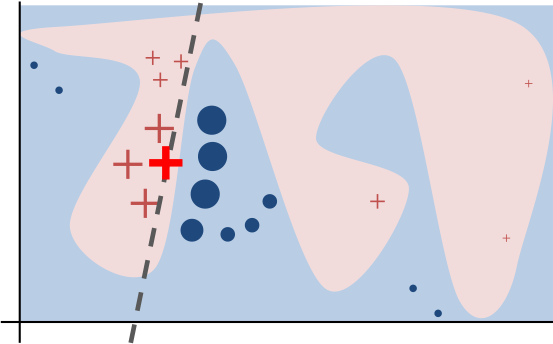

*The intuition behind LIME. Figure from the LIME repository (Ribeiro, Singh & Guestrin, 2016; © 2016 Marco Tulio Ribeiro, BSD licence).*

| In the figure | What it means |
| :--- | :--- |
| blue / pink background | the decision function of the black box $f$: complex, no single line can describe it |
| bold red cross | the instance we want to explain (here: sentence #370) |
| red crosses and blue dots | **perturbed copies** of the instance (copies with some changes), with the class predicted by the black box |
| size of a symbol | its **weight**: copies close to the instance count more |
| dashed line | the **explanation**: a linear model that is faithful **near** the instance, not everywhere |

The Earth is round, but the street in front of your house looks flat: in the same way, around **one** instance a black box can be approximated by a **linear model** (a weighted sum of the features), and the coefficients of that linear model are the explanation.

## 2.2 The formula

$$\xi(x) \;=\; \arg\min_{g \in G} \; \mathcal{L}\bigl(f, g, \pi_x\bigr) \;+\; \Omega(g)$$

*"Among the simple models $g$, choose the one that best imitates $f$ near $x$, while staying simple."*

- $f$: the black box; $x$: the instance to explain; $g \in G$: a simple (linear) model;
- $\mathcal{L}(f, g, \pi_x) = \sum_{z} \pi_x(z)\,\bigl(f(z) - g(z')\bigr)^2$: **local fidelity loss**, a weighted squared error over perturbed copies $z$ of $x$, where $z'$ is their 0/1 representation (for each word: "kept or removed?");
- $\pi_x(z) = \exp\!\bigl(-D(x,z)^2 / 2\sigma^2\bigr)$: **proximity kernel**, copies similar to $x$ weigh more ($D$ = distance from $x$, $\sigma$ = kernel width);
- $\Omega(g)$: **complexity** of $g$ (e.g. number of features used), kept small so that a human can read it.

## 2.3 The recipe in 4 steps (text)

| Step | What LIME does to explain sentence $x$ |
| :--- | :--- |
| **1. Perturb** | create many **copies** of $x$. For each copy LIME draws **how many** words to remove (a random number between 1 and $d$, the number of distinct words of $x$, all equally likely), then **which** ones (at random) |
| **2. Predict** | ask the black box P(positive) for every copy |
| **3. Weight** | copies with **few words removed** are closer to $x$ and weigh more |
| **4. Fit** | a **weighted linear regression**: "word kept" (1/0) → P(positive). *Weighted* = copies with a larger weight count more in the fit |

**Are words taken from other sentences?** No: a copy can only **lose** words of $x$, it never gains words from other sentences (tabular LIME, instead, takes values from other instances of the training data).

**How many words are removed in each copy?** Nobody chooses it: it is **random**, between 1 and $d$, so some copies lose a single word and others almost all of them (about half on average). With `bow=True` (the default), a removed word disappears everywhere it appears in the sentence.

**What you can set** (in `LimeTextExplainer` and in its method `explain_instance`):

| Parameter | Default | What it controls |
| :--- | :--- | :--- |
| `num_samples` | 5,000 (we use 1,000: short sentences) | how many copies |
| `kernel_width` | 25 (on a distance from 0 to 100) | how quickly a copy loses weight when more words are removed |
| `bow` | `True` | remove a word everywhere it appears (`True`) or one occurrence at a time (`False`) |
| `num_features` | 10 | how many words the explanation shows |

The **coefficients** of step 4 are the explanation: **+** pushes toward *positive*, **−** toward *negative*.

## 2.4 🔧 LIME by hand (no library)

We explain sentence **#370** of the test set. Read it first: is it positive or negative?

In [ ]:
# ==========================================
# 4. THE SENTENCE TO EXPLAIN
# ==========================================

DOC = 370
sentence = X_test_txt[DOC]
p_pos = text_model.predict_proba([sentence])[0, 1]           # column 1 = 'positive'

print(sentence)
print(f"\nTrue label: {y_test_txt[DOC].upper()}")
print(f"Model:      P(positive) = {p_pos:.3f} -> {text_model.predict([sentence])[0].upper()} ❌")

In [ ]:
# ==========================================
# 5. LIME BY HAND - STEP 1 (PERTURB) AND STEP 2 (PREDICT)
# ==========================================

# Split the sentence into words and separators (spaces, punctuation), keeping their order
pieces = re.split(r"(\W+)", sentence)
words = list(dict.fromkeys(p for p in pieces if re.fullmatch(r"\w+", p)))   # distinct words = our features
d = len(words)
N_SAMPLES = 1000
rng = np.random.RandomState(0)               # random numbers with a fixed seed

# Z[i, j] = 1 if word j is KEPT in copy i, 0 if it is REMOVED. Row 0 = the original sentence.
# For each copy: draw HOW MANY words to remove (1 to d, all equally likely), then WHICH ones (at random)
Z = np.ones((N_SAMPLES, d), dtype=int)
for i in range(1, N_SAMPLES):
    n_removed = rng.randint(1, d + 1)
    Z[i, rng.choice(d, n_removed, replace=False)] = 0

def remove_words(z):
    # Rebuild the sentence without the removed words (all their occurrences)
    removed = {w for w, keep in zip(words, z) if not keep}
    return "".join(p for p in pieces if p not in removed)

copies = [remove_words(z) for z in Z]
p_copies = text_model.predict_proba(copies)[:, 1]      # STEP 2: ask the black box P(positive) of every copy

removed = d - Z.sum(axis=1)                            # number of words removed, copy by copy
print(f"{d} distinct words -> {N_SAMPLES:,} perturbed copies.")
print(f"Words removed per copy: from {removed[1:].min()} to {removed[1:].max()}, on average {removed[1:].mean():.1f}. Three copies:\n")
for i in [1, 2, 3]:
    print(f"words removed: {removed[i]} | P(positive) = {p_copies[i]:.2f} | {' '.join(copies[i].split())}")

In [ ]:
# ==========================================
# 6. LIME BY HAND - STEP 3 (WEIGHT) AND STEP 4 (FIT)
# ==========================================

# STEP 3: distance from the original sentence. LIME uses 1 - cosine similarity between the 0/1 vectors
# of the copy and of the original; with words only removed, the cosine similarity is sqrt(kept / d)
distance = 1 - np.sqrt(Z.sum(axis=1) / d)               # 0 = identical, 1 = everything removed
KERNEL_WIDTH = 0.25                                     # LIME's default for text (25 on a 0-100 scale)
weights = np.exp(-distance**2 / (2 * KERNEL_WIDTH**2))  # Gaussian kernel pi_x(z): 1 for the original, smaller far away
print("Weight of a copy, by number of words removed:")
print({k: round(float(np.exp(-(1 - np.sqrt((d - k) / d))**2 / (2 * KERNEL_WIDTH**2))), 2) for k in range(d + 1)}, "\n")

# STEP 4: weighted linear regression   "word kept (1/0)"  ->  P(positive)
# Ridge = linear regression with a small penalty (alpha) that keeps the coefficients stable (LIME's default)
surrogate = Ridge(alpha=1.0).fit(Z, p_copies, sample_weight=weights)

lime_by_hand = pd.Series(surrogate.coef_, index=words).sort_values(key=abs, ascending=False)
print("LIME weights (by hand):   + pushes toward POSITIVE,  - pushes toward NEGATIVE\n")
print(lime_by_hand.round(3).to_string())

In [ ]:
# ==========================================
# 7. WHAT HAPPENS WHEN A WORD IS REMOVED?
# ==========================================

# For every word: take the copies that contain it, remove ONLY that word, and ask the black box again.
# We compare the average P(positive) of these copies WITH the word and of the same copies WITHOUT it
effect = {}
for j, word in enumerate(words):
    has_word = Z[:, j] == 1                               # the copies that contain the word
    without = Z[has_word].copy()
    without[:, j] = 0                                     # the same copies, without the word
    effect[word] = [p_copies[has_word].mean(),
                    text_model.predict_proba([remove_words(z) for z in without])[:, 1].mean()]
effect = pd.DataFrame(effect, index=["copies WITH the word", "the same copies WITHOUT it"]).T

# One row per word: the largest LIME weight at the top
dumbbell(effect.loc[lime_by_hand.index[::-1]], "average P(positive) of the copies",
         f"Sentence #{DOC}: what happens when ONE word is removed from the copies?")

### 💡 What did we just see?

- Removing ***recommend*** makes the copies much less positive (the blue dot is far to the left of the gray one). LIME's linear model summarises this effect with a large **positive weight** for *recommend*.
- Removing ***not*** changes **nothing**: the two dots coincide. For this model the word *not* does not exist, and LIME gives it a weight of about 0. The same happens to *I*, *would*, *this*, *to* and *anyone*.

**That is all LIME does**: perturb → predict → weight → fit.

# QUESTION: "WOULD NOT RECOMMEND" MEANS THE OPPOSITE OF "WOULD RECOMMEND". WHY DOES THE MODEL NOT REACT TO "NOT"?

Keep this question in mind: we answer it in Part 3.

## 2.5 📦 The same with the `lime` library

`LimeTextExplainer` runs the same 4 steps (`bow=True`: a word is removed wherever it appears).

In [ ]:
# ==========================================
# 8. LIME WITH THE LIBRARY
# ==========================================

# class_names in the same order as the model's columns: ['negative', 'positive']
text_explainer = LimeTextExplainer(class_names=list(text_model.classes_), bow=True, random_state=42)
exp_doc = text_explainer.explain_instance(sentence, text_model.predict_proba, num_features=d, num_samples=1000)

# Interactive view: predicted probabilities | word weights | highlighted sentence
show_lime(exp_doc, text=True)

In [ ]:
# ==========================================
# 9. A QUICK CHECK: BY HAND vs LIBRARY
# ==========================================

# Our weights (Section 2.4) next to the library's, one row per word
library = pd.Series(dict(exp_doc.as_list()))           # word -> weight, according to the library
pd.DataFrame({"by hand": lime_by_hand, "lime library": library}).loc[library.index].round(3)

✅ Same words, same signs, similar sizes (the copies are random, so the numbers are not identical). **From now on we use the library.**

## 2.6 ✅ Can we trust this explanation? Fidelity

An explanation is judged with a **different yardstick** than the model:

| | It compares... | It answers... | In this notebook |
| :--- | :--- | :--- | :--- |
| **Accuracy** | the model's predictions with the **true labels** | *is the model right?* | the test accuracy of Part 1 |
| **Fidelity** | the explanation with the **model's predictions** | *does the explanation describe what the model really does?* | the local $R^2$ below |

⚠️ We never judge an explanation by its accuracy. A **faithful** explanation of a **wrong** prediction is exactly what we need to discover *why* the model is wrong.

LIME's explanation is the linear model $g$, so its fidelity is how well $g$ reproduces the black box $f$ **on the copies**, each copy weighted by its closeness to the sentence (the weights $\pi_x$ of the formula). It is measured with the **weighted $R^2$**:

$$R^2_{\text{local}} \;=\; 1 - \frac{\sum_z \pi_x(z)\,\bigl(f(z) - g(z')\bigr)^2}{\sum_z \pi_x(z)\,\bigl(f(z) - \bar f\bigr)^2}$$

- the **numerator** is exactly LIME's loss $\mathcal{L}(f, g, \pi_x)$: the weighted errors of $g$;
- the **denominator** is the weighted variability of the black box on the copies ($\bar f$ = weighted average prediction);
- $R^2 = 1$: $g$ reproduces the black box perfectly around the sentence; $R^2 = 0$: $g$ is no better than always answering $\bar f$.

The library computes it for every explanation (`explanation.score`). We also check how it changes when the explanation shows **fewer features** (the term $\Omega(g)$ of the formula): we repeat the explanation on **the same copies** (same random seed), allowing the linear model to use only the $K$ most useful features.

In [ ]:
# ==========================================
# 10. FIDELITY OF THE EXPLANATION
# ==========================================

# 1) The fidelity of the explanation of Section 2.5: the library stores the local R² in .score
#    and the prediction of its linear model at the sentence, g(x), in .local_pred
print(f"Local fidelity (weighted R²): {exp_doc.score:.2f}")
print(f"At the sentence: black box f(x) = {p_pos:.3f} | LIME's linear model g(x) = {exp_doc.local_pred[0]:.3f}\n")

# 2) Simpler explanations: the same 1,000 copies (same seed), but a linear model with only K words
r2_by_k = []
for k in range(1, d + 1):
    explainer_k = LimeTextExplainer(class_names=list(text_model.classes_), bow=True, random_state=42)
    r2_by_k.append(explainer_k.explain_instance(sentence, text_model.predict_proba, num_features=k, num_samples=1000).score)

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(range(1, d + 1), r2_by_k, marker="o", color=BLUE)
for k, r2 in enumerate(r2_by_k, start=1):
    ax.annotate(f"{r2:.2f}", (k, r2), xytext=(0, 7), textcoords="offset points", ha="center", color=INK, fontsize=8)
ax.set_xticks(range(1, d + 1))
ax.set_ylim(0, 1.1)
ax.set_xlabel("number of words in the explanation")
ax.set_ylabel("local fidelity (weighted R²)")
ax.set_title(f"Sentence #{DOC}: how faithful is an explanation with K words?", loc="left")
ax.yaxis.grid(True, color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

### 💡 What does fidelity tell us here?

- The fidelity is **high** (local $R^2$ ≈ 0.95) and $g(x)$ is close to $f(x)$: this explanation describes the black box well. So when LIME says that *not* has no effect, we can believe it: the model **really** ignores *not*.
- Look at the curve: with **one word** (*recommend*) the fidelity is already at its maximum, and the other words add **nothing**. Of the 8 words of the sentence, the model practically listens to one.
- In general, an explanation with fewer features is simpler but less faithful: this is the trade-off between $\mathcal{L}$ (fidelity) and $\Omega$ (simplicity) in the formula of Section 2.2. Here it costs nothing, because the model itself uses almost only one word.

> 📏 **Rule**: always report the fidelity together with a LIME explanation: it tells you how much to trust its numbers.

### 💡 From the mechanism to the practice

| Because LIME... | ...it can | ...but |
| :--- | :--- | :--- |
| only needs `predict_proba` on perturbed copies | explain **any** model (here a neural network it knows nothing about) | every explanation costs hundreds or thousands of model calls |
| removes words | show which words **matter** and which are **ignored**: if removing a word changes nothing, its weight is 0 | perturbed copies are often not natural sentences |
| fits a **linear** model on a **neighbourhood** | give a short, readable list of +/− weights | it is only valid near $x$: check its **fidelity** |
| uses **random** sampling | — | results change with `num_samples` and the seed (Part 4) |

# 🐛 Part 3 — Debugging the model with LIME

## 3.1 Is "not" a one-off?

One explanation is an anecdote. Let's explain **four other sentences** of the test set that the model gets **wrong**, two negative and two positive, and look at the **negations** (*not*, *no*, *never*, ...).

In [ ]:
# ==========================================
# 11. LIME ON FOUR MISTAKES
# ==========================================

# Negation words: they turn the meaning of a sentence around ("good" vs "not good")
NEGATIONS = ['not', 'no', 'never', 'nothing', 'none', 'nobody', 'neither', 'nor', 'cannot', 'without']
# True for the test sentences that contain at least one negation (words in lower case, punctuation dropped)
has_negation = np.array([any(w in NEGATIONS for w in re.findall(r"\w+", s.lower())) for s in X_test_txt])

MISTAKES = [218, 347, 110, 356]           # four test sentences that the model gets wrong
rows = []
for i in MISTAKES:
    e = text_explainer.explain_instance(X_test_txt[i], text_model.predict_proba, num_features=30, num_samples=1000)
    w = dict(e.as_list())                                         # word -> LIME weight
    top3 = sorted(w.items(), key=lambda kv: -abs(kv[1]))[:3]      # the 3 words with the largest weights
    rows.append({"sentence": X_test_txt[i],
                 "true label": y_test_txt[i],
                 "model: P(positive)": round(text_model.predict_proba([X_test_txt[i]])[0, 1], 2),
                 "3 most important words": ", ".join(f"{k} ({v:+.2f})" for k, v in top3),
                 "negations": ", ".join(f"{k} ({v:+.2f})" for k, v in w.items() if k.lower() in NEGATIONS)})
pd.DataFrame(rows)

💡 In all four sentences the model follows the words that **would** be positive or negative on their own (*impressed*, *worked*, *complain*, *trouble*, ...), while the negations (*not*, *no*, *never*) have a weight of about **0**: the model does not react to them.

# QUESTION: WHY WOULD A MODEL BASED ON A NEURAL NETWORK, TRAINED ON MILLIONS OF SENTENCES, IGNORE "NOT"?

## 3.2 The culprit

Let's look at what the network actually **receives** after the cleaning step of Part 1.

In [ ]:
# ==========================================
# 12. WHAT DOES THE MODEL ACTUALLY READ?
# ==========================================

for i in [DOC] + MISTAKES:
    print(f"original: {X_test_txt[i]}")
    print(f"cleaned : {clean(X_test_txt[i])}\n")
print("Are they stop words?", {w: w in STOP_WORDS for w in ['not', 'no', 'never', 'nothing', 'without', 'very', 'but']})

ok = text_model.predict(X_test_txt) == np.array(y_test_txt)          # True where the model is right
print(f"\nAccuracy on the {has_negation.sum()} test sentences WITH a negation:     {ok[has_negation].mean():.1%}")
print(f"Accuracy on the {(~has_negation).sum()} test sentences WITHOUT a negation: {ok[~has_negation].mean():.1%}")

🐛 **Found it.** *not*, *no*, *never*, *nothing*, *without*, *very*, *but* are all on scikit-learn's stop-word list, so the **cleaning step deletes them before the network can read them**: *"I would not recommend this item to anyone."* becomes *"recommend item"*, and *"Never had anything to complain about here."* becomes *"complain"*. On the sentences with a negation the model is right much less often than on the others.

Stop-word lists were made for search engines and word-counting models, where *not* is just a very frequent word. For sentiment it is one of the most important words, and an embedding model **can** understand it... if we let it read it.

## ✍️ Exercise — Fix the cleaning

1. **Step 1.** Put in `words_to_keep` the words that LIME showed the model needs (for example the negations): the cleaning will not remove them any more. Re-run the two cells.
2. **Step 2.** An embedding model is made to read **whole sentences**. Try `CLEAN_TEXT = False` (no cleaning at all) and re-run the two cells.

⏱️ Each retraining takes less than a minute (all the training sentences go through the network again).

In [ ]:
# ==========================================
# 13. ✍️ EXERCISE: YOUR FIX
# ==========================================

words_to_keep = []          # 👉 Step 1: e.g. ['not', 'never'] = words that the cleaning must NOT remove
CLEAN_TEXT = True           # 👉 Step 2: False = no cleaning at all

new_stop_words = STOP_WORDS - set(words_to_keep)       # the stop-word list without the words to keep
fixed_text_model = train_sentiment_model(X_train_txt, y_train_txt, clean_text=CLEAN_TEXT, stop_words=new_stop_words)

In [ ]:
# ==========================================
# 14. BEFORE vs AFTER
# ==========================================

ok_new = fixed_text_model.predict(X_test_txt) == np.array(y_test_txt)   # True where the fixed model is right
results = pd.DataFrame({
    "Original model": [ok.mean(), ok[has_negation].mean(), ok[~has_negation].mean()],
    "Fixed model": [ok_new.mean(), ok_new[has_negation].mean(), ok_new[~has_negation].mean()]},
    index=["all test sentences", "sentences WITH a negation", "sentences WITHOUT a negation"])
dumbbell(results, "accuracy", "Accuracy on the test set, before and after the fix")
print(f"words_to_keep = {words_to_keep} | CLEAN_TEXT = {CLEAN_TEXT}")
if CLEAN_TEXT and not words_to_keep:
    print("ℹ️ Nothing changed: the fixed model is identical to the original. Use what LIME showed you!")

# Sentence #370 explained again, with the fixed model
print(f"\nSentence #{DOC}: P(positive) = {fixed_text_model.predict_proba([sentence])[0, 1]:.3f} with the fixed model")
show_lime(text_explainer.explain_instance(sentence, fixed_text_model.predict_proba, num_features=d, num_samples=1000), text=True)

<details>
<summary>✅ <b>Solution</b> (click to open)</summary>

```python
words_to_keep = ['not', 'no', 'never', 'nothing', 'none', 'nobody', 'neither', 'nor', 'cannot', 'without']   # Step 1
CLEAN_TEXT = False                                                                                         # Step 2
```

- **Step 1** (keep the negations): the test accuracy goes from about 86% to about 92%, and on the sentences with a negation from about 63% to about 91%.
- **Step 2** (no cleaning): about 96% on all the test sentences, and about 96% also on the sentences with a negation (they were 63%!). An embedding model needs the **whole** sentence: also the other stop words (*too*, *very*, *but*, ...) carry meaning for a model that reads.
- Sentence #370 is now classified as **negative**, and LIME shows *not* as its most important word.

</details>

# QUESTION: THE TEST ACCURACY OF PART 1 LOOKED GOOD (86%). WITHOUT THE EXPLANATIONS, WOULD YOU HAVE LOOKED FOR THE PROBLEM IN THE CLEANING STEP?

# ⚠️ Part 4 — The limits of LIME

LIME learns from **random** perturbations: with too few of them, the explanation changes from run to run. Let's explain sentence #370 three times (3 seeds) with 50 and with 1,000 perturbations.

In [ ]:
# ==========================================
# 15. IS LIME STABLE?
# ==========================================

rows = []
for n in [50, 1000]:                  # number of copies
    for seed in [0, 1, 2]:            # three different random seeds
        e = LimeTextExplainer(class_names=list(text_model.classes_), bow=True, random_state=seed)
        e = e.explain_instance(sentence, text_model.predict_proba, num_features=3, num_samples=n)
        rows.append({"num_samples": n, "seed": seed,
                     "top-3 words": ",  ".join(f"{w} ({v:+.2f})" for w, v in e.as_list()),
                     "local R²": round(e.score, 2)})
pd.DataFrame(rows)

With 50 copies the weights move from run to run; with 1,000 the explanation is stable.

**The limits of LIME** follow from its mechanism:
- **Instability**: use enough `num_samples` and check with several seeds.
- **Locality**: one explanation = one sentence; no global view of the model (we needed several explanations to see the pattern).
- **Approximation**: the linear model may fit the black box poorly: always check its **fidelity**; its weights do not add up to the prediction.
- **Unnatural copies**: sentences with random words removed are not real sentences.

# 📌 Summary

| What LIME revealed | What we did | Result |
| :--- | :--- | :--- |
| *not*, *no*, *never* have **zero weight**: the cleaning step removes them before the model reads the sentence | kept the words, then removed the cleaning | test accuracy from about 86% to about 96%; on sentences with a negation from about 63% to about 96% |
| The explanation of sentence #370 is **faithful** (local $R^2$ ≈ 0.95) | trusted its message | — |

### 🔑 The golden rules

> **Accuracy** tells you how often the **model** is right. **Fidelity** tells you whether the **explanation** describes the model. A faithful explanation of a **wrong** prediction tells you **why** the model is wrong, and that is the first step to make it right.

➡️ **Notebook 4** explains **this same model** with **SHAP**: contributions that **add up exactly** to the prediction, words the model ignores get **exactly 0**, and a **global** view of the whole model.

## 🎯 Final exercises

1. **Probe the model.** Write your own reviews, e.g. `"The battery does not last long."` and `"The waiter was not rude at all."`. Compare `text_model.predict_proba([...])` and `fixed_text_model.predict_proba([...])`, and explain them with LIME.
2. **Kernel width and fidelity.** Explain sentence #370 again with `LimeTextExplainer(class_names=list(text_model.classes_), kernel_width=5, random_state=42)` and then with `kernel_width=100` (the default is 25), and print `.score` and `.as_list()`. How do the fidelity and the weights change, and why?
3. **The mistakes that remain.** Find a test sentence that the **fixed** model still gets wrong and explain it with LIME. Can you see a pattern (irony, mixed opinions, ...)?
4. **A word in context.** With the fixed model, explain three sentences that contain *but*. Does *but* get a weight now? Is it always in the same direction?

---

### References

- Ribeiro, M. T., Singh, S., Guestrin, C. (2016). *"Why Should I Trust You?": Explaining the Predictions of Any Classifier*. KDD 2016.
- Kotzias, D., Denil, M., de Freitas, N., Smyth, P. (2015). *From Group to Individual Labels Using Deep Features*. KDD 2015. Dataset: *Sentiment Labelled Sentences*, UCI Machine Learning Repository, <https://doi.org/10.24432/C57604> (CC BY 4.0).
- Xiao, S. et al. (2023). *C-Pack: Packaged Resources To Advance General Chinese Embedding* (the BGE embedding models). arXiv:2309.07597.
- Reimers, N., Gurevych, I. (2019). *Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks*. EMNLP 2019.
- Molnar, C. *Interpretable Machine Learning* (free online book): <https://christophm.github.io/interpretable-ml-book/>
- LIME library: <https://github.com/marcotcr/lime>